# Suplemento para qualificação: acurácia e F1 na MADA

**Conclusão:** acurácia e F1 exigem rótulos de referência. Não exigem que esses rótulos sejam uma verdade objetiva incontestável. Aqui, os consensos majoritários de cada grupo são **referências operacionais distintas**. As métricas abaixo medem aderência à fonte anotativa correspondente; não validam o sentimento verdadeiro nem demonstram qual grupo está correto.

Suplemento independente, produzido a partir das predições out-of-fold já salvas, sem novos treinamentos ou alteração dos resultados certificados. As tabelas e figuras estão incorporadas neste notebook e podem ser consultadas sem executar as células.


## O que a metodologia propõe

1. A Fase 1 consolida anotações por grupo e obtém o MQD-1222.
2. A Fase 2 treina dois modelos de cada algoritmo, cada um com os rótulos de um grupo, nos mesmos cinco folds (estratificação masculina, shuffle e seed 42). O TF-IDF é ajustado apenas no treino.
3. A medida principal compara a concordância anotativa à preditiva: **Δκ = κ_anotativo − média dos κ_preditivos dos folds**. Δκ positivo indica redução da concordância segundo esse protocolo, sem estabelecer uma verdade externa.
4. Acurácia e F1 ponderado já são calculados na célula 19 (índice começando em zero) da Fase 2, em relação à própria fonte, e exportados em `metricas-modelos-pareados.csv`.

**Distinção para a banca:** concordância entre os dois modelos não é acurácia de classificação. As matrizes entre predições da Fase 2 são tabelas de contingência; as métricas de classificação comparam cada predição ao respectivo rótulo anotativo de teste.


In [1]:
from pathlib import Path
import importlib.util
from IPython.display import display, Image
raiz = Path.cwd()
if not (raiz / 'suplemento-metricas-qualificacao.py').exists():
    raise FileNotFoundError('Execute este notebook na raiz do repositório mada.')
spec = importlib.util.spec_from_file_location('suplemento', raiz / 'suplemento-metricas-qualificacao.py')
mod = importlib.util.module_from_spec(spec)
spec.loader.exec_module(mod)
tabelas = mod.analisar()
print('Métricas reconstruídas e verificadas; nenhum treinamento executado.')

Métricas reconstruídas e verificadas; nenhum treinamento executado.


## Tabela principal — média dos cinco folds

Valores entre 0 e 1. **F1 ponderado** é a média dos F1 por classe ponderada pelo suporte no teste, conforme a implementação original; F1 macro atribui o mesmo peso às três classes. DP é desvio-padrão amostral entre folds (ddof=1), não intervalo de confiança. `ganho_acuracia_pp` é a diferença descritiva para o baseline em pontos percentuais.

As médias de acurácia e F1 ponderado e os DP de acurácia foram reconstruídos e comparados aos arquivos certificados com tolerância absoluta de 1e-12. O DP de F1 e F1 macro são acréscimos deste suplemento.


In [2]:
display(tabelas['resumo-fidelidade-fonte'])

modelo,grupo,acuracia_media,acuracia_dp,f1_ponderado_medio,f1_ponderado_dp,f1_macro_medio,f1_macro_dp,baseline_acuracia,baseline_f1_ponderado,ganho_acuracia_pp
SVM,masculino,0.366594,0.022707,0.339008,0.020598,0.308124,0.021390,0.393617,0.222349,-2.702242
SVM,feminino,0.343730,0.027590,0.339506,0.031498,0.334092,0.029603,0.364982,0.195457,-2.125125
NB,masculino,0.369896,0.026826,0.327544,0.025889,0.291356,0.024189,0.393617,0.222349,-2.372031
NB,feminino,0.350281,0.030105,0.339396,0.032936,0.332876,0.029242,0.364982,0.195457,-1.470057
RF,masculino,0.367414,0.032177,0.342307,0.036153,0.311492,0.038735,0.393617,0.222349,-2.620274
RF,feminino,0.335524,0.019353,0.332544,0.021708,0.328058,0.022072,0.364982,0.195457,-2.945801
LR,masculino,0.359251,0.034038,0.334989,0.029564,0.306291,0.027426,0.393617,0.222349,-3.436601
LR,feminino,0.348645,0.029247,0.345055,0.030315,0.339668,0.028740,0.364982,0.195457,-1.633657


## Figura de síntese para os slides

Acurácia e F1 ponderado são médias dos cinco folds; os losangos mostram o baseline de classe majoritária escolhido no treino e avaliado no teste. Não há barras de DP nesses dois painéis. O terceiro painel apresenta Δκ e os IC95% já certificados, conferidos contra o bootstrap revisado. Esses IC mantêm κ anotativo fixo e reamostram as predições pareadas dentro de cada fold.


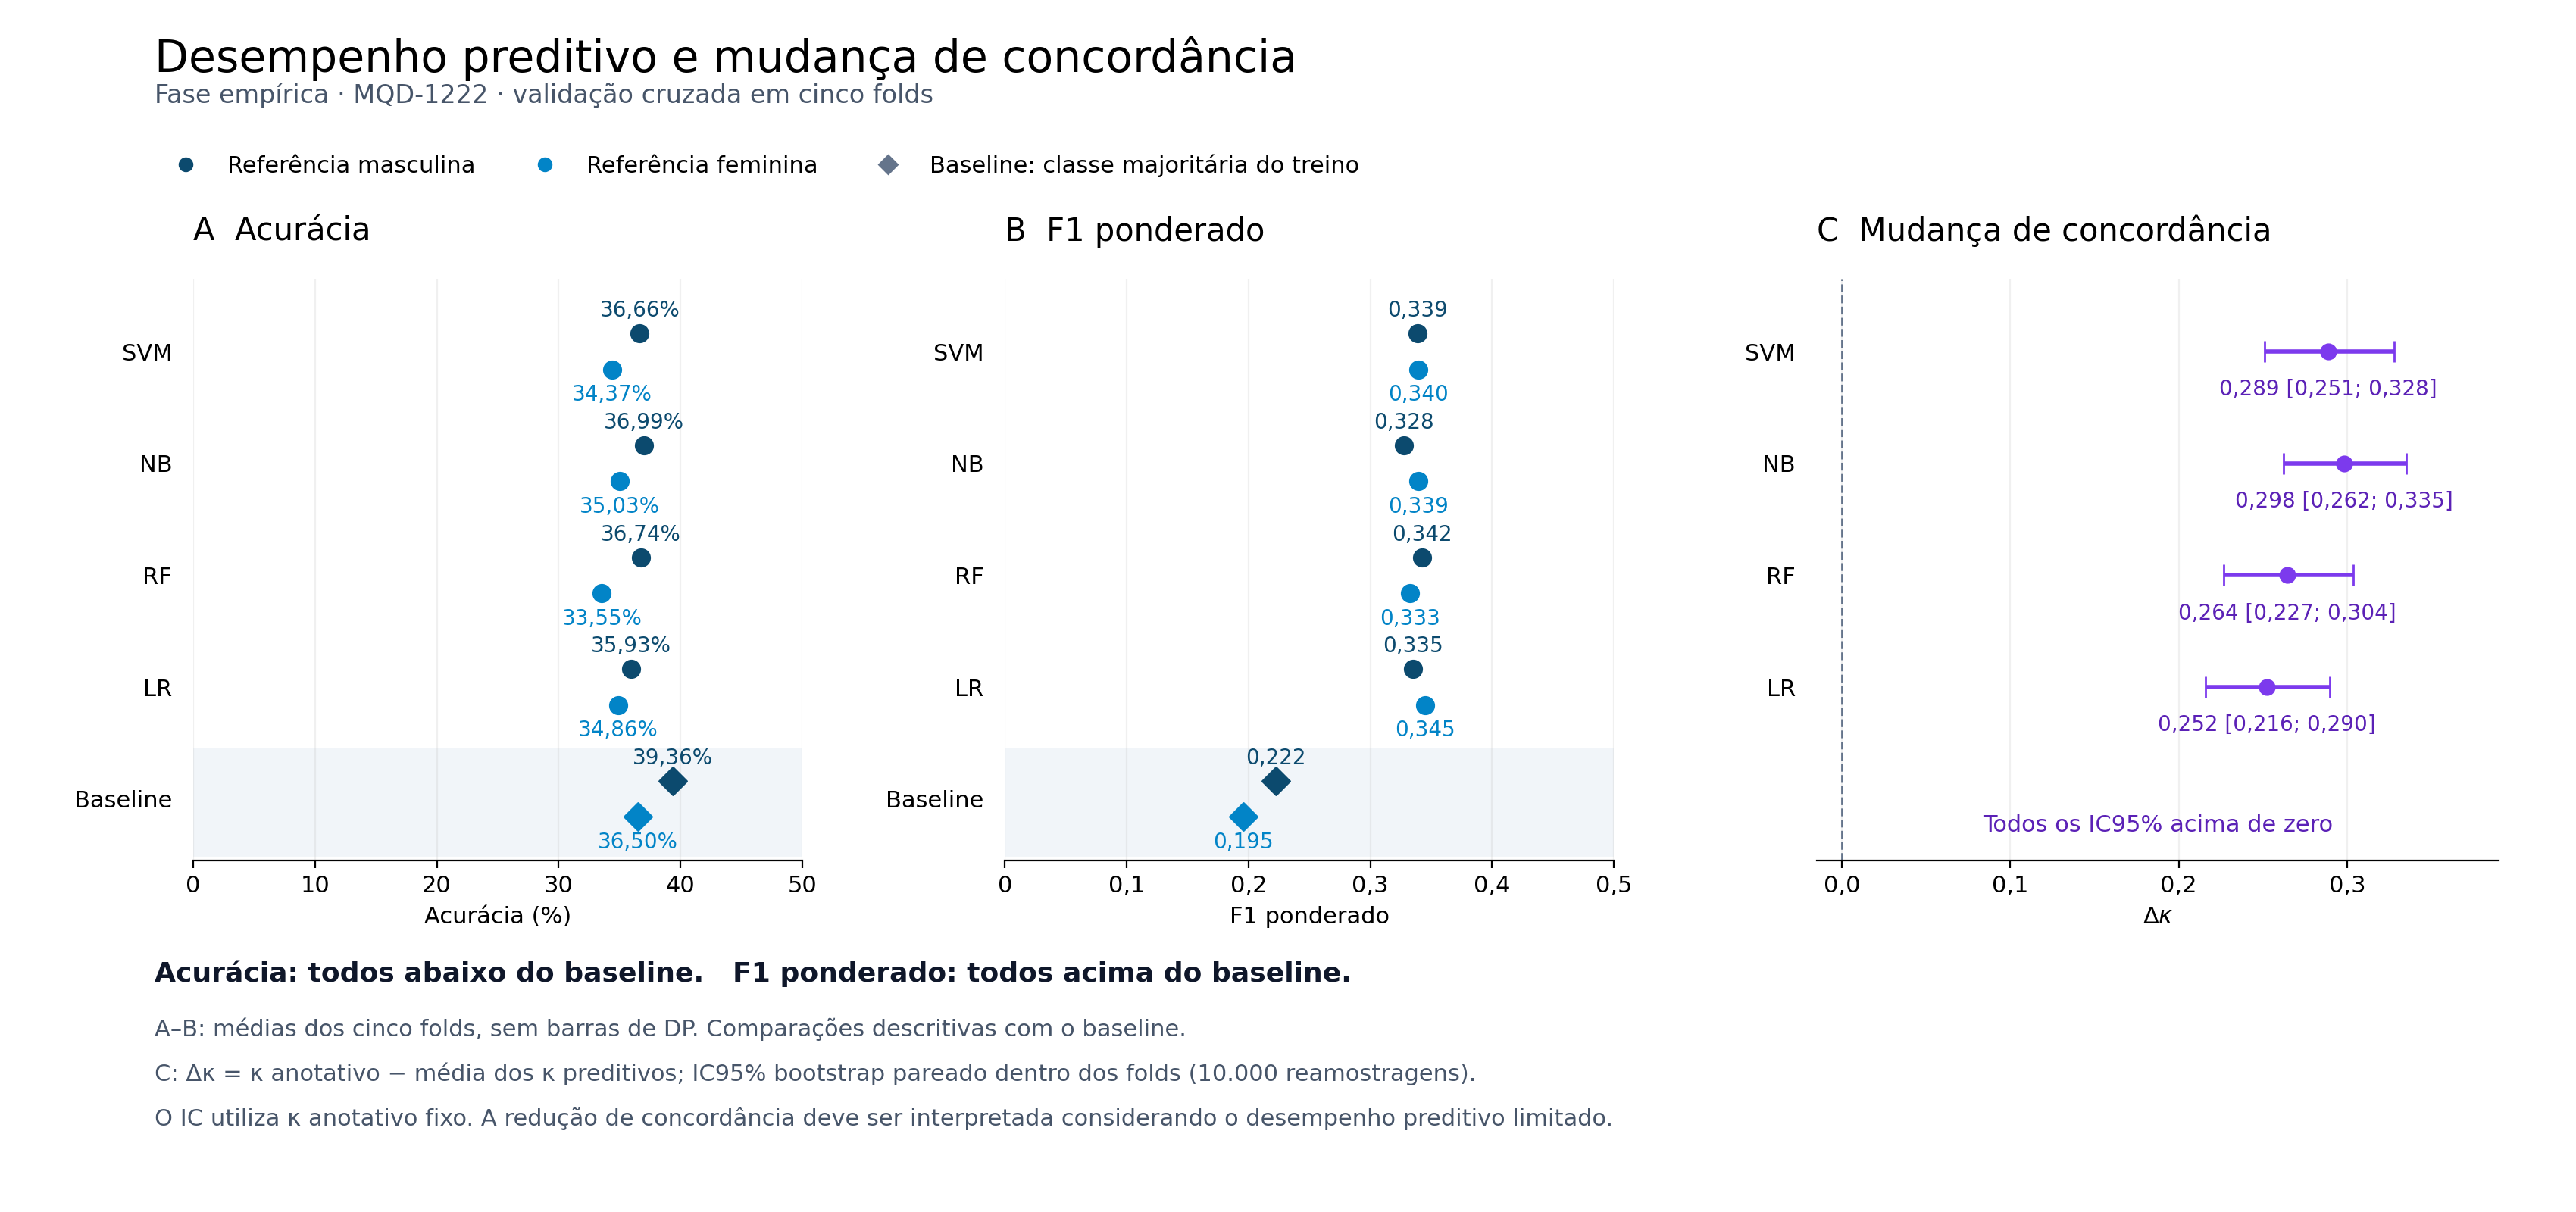

In [3]:
display(Image(filename=str(mod.OUT / 'sintese-desempenho-delta-kappa.png')))

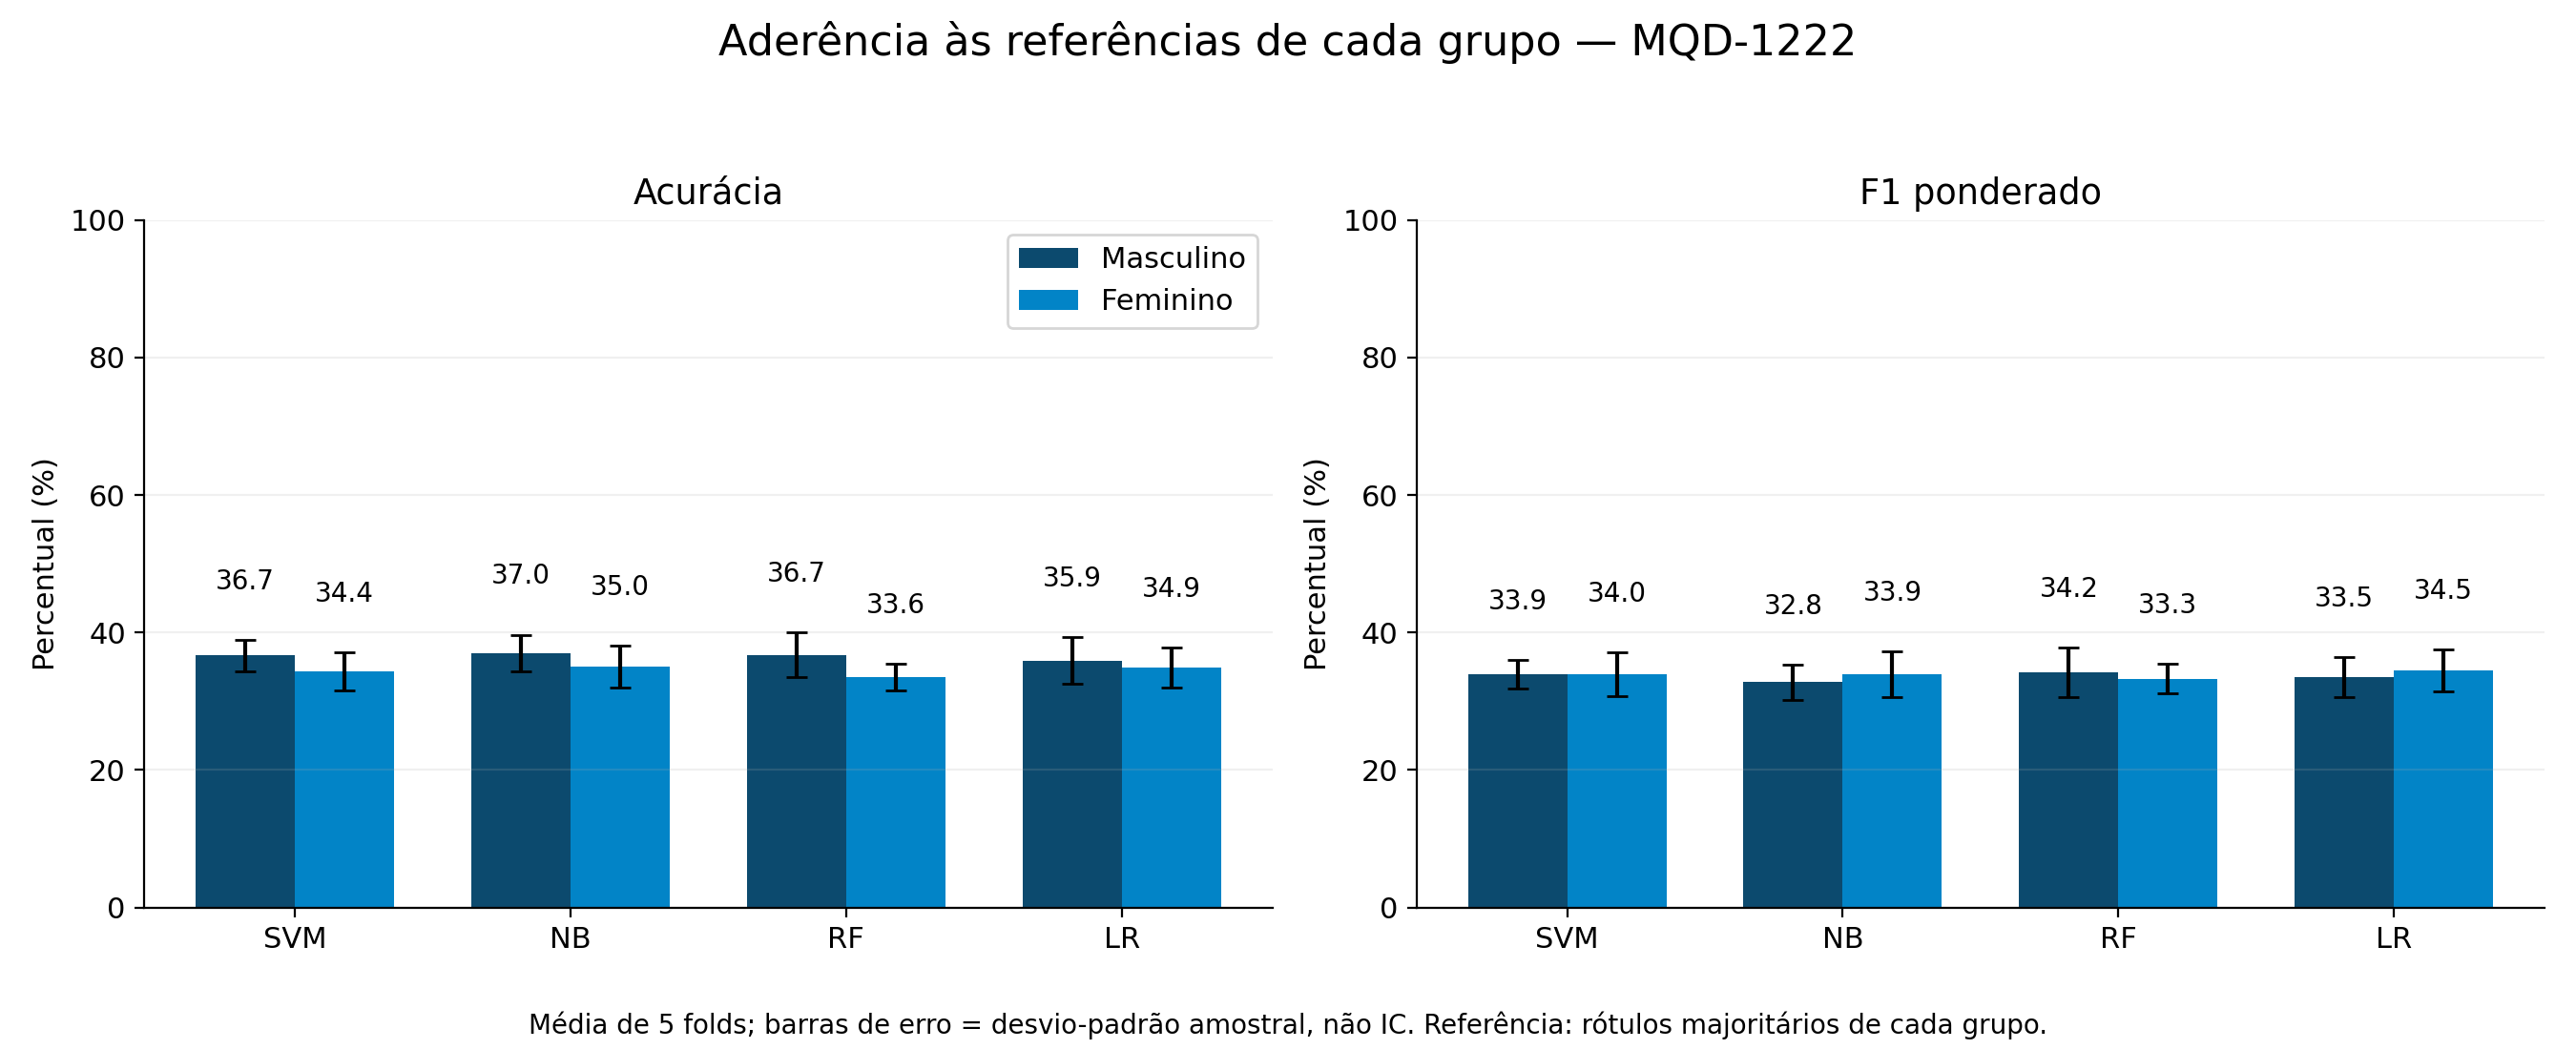

In [4]:
display(Image(filename=str(mod.OUT / 'acuracia-f1-fontes.png')))

## Baseline e limites da interpretação

O baseline sempre prediz a classe majoritária **do treino de cada fold e grupo**, sem acessar os rótulos de teste. Empates são resolvidos pelo menor código de classe. **Todos os modelos ficam abaixo desse baseline em acurácia:** o baseline obtém 39,36% na referência masculina e 36,50% na feminina. As diferenças dos modelos ficam entre −3,44 e −1,47 pontos percentuais. Em contrapartida, todos superam o F1 ponderado do baseline (0,2223 e 0,1955, respectivamente). A diferença entre as conclusões decorre de as métricas avaliarem aspectos distintos da distribuição dos erros. São comparações descritivas; não há teste de superioridade neste suplemento.

Uma acurácia próxima de 1/3, isoladamente, não permite concluir desempenho equivalente ao acaso: a distribuição de classes e a regra do baseline precisam ser consideradas. Tampouco a redução de κ prova que os modelos aprenderam diferenças substantivas de perspectiva; erros, instabilidade e distribuições marginais também podem afetar a concordância. As métricas de aderência complementam Δκ e recomendam cautela na interpretação substantiva.


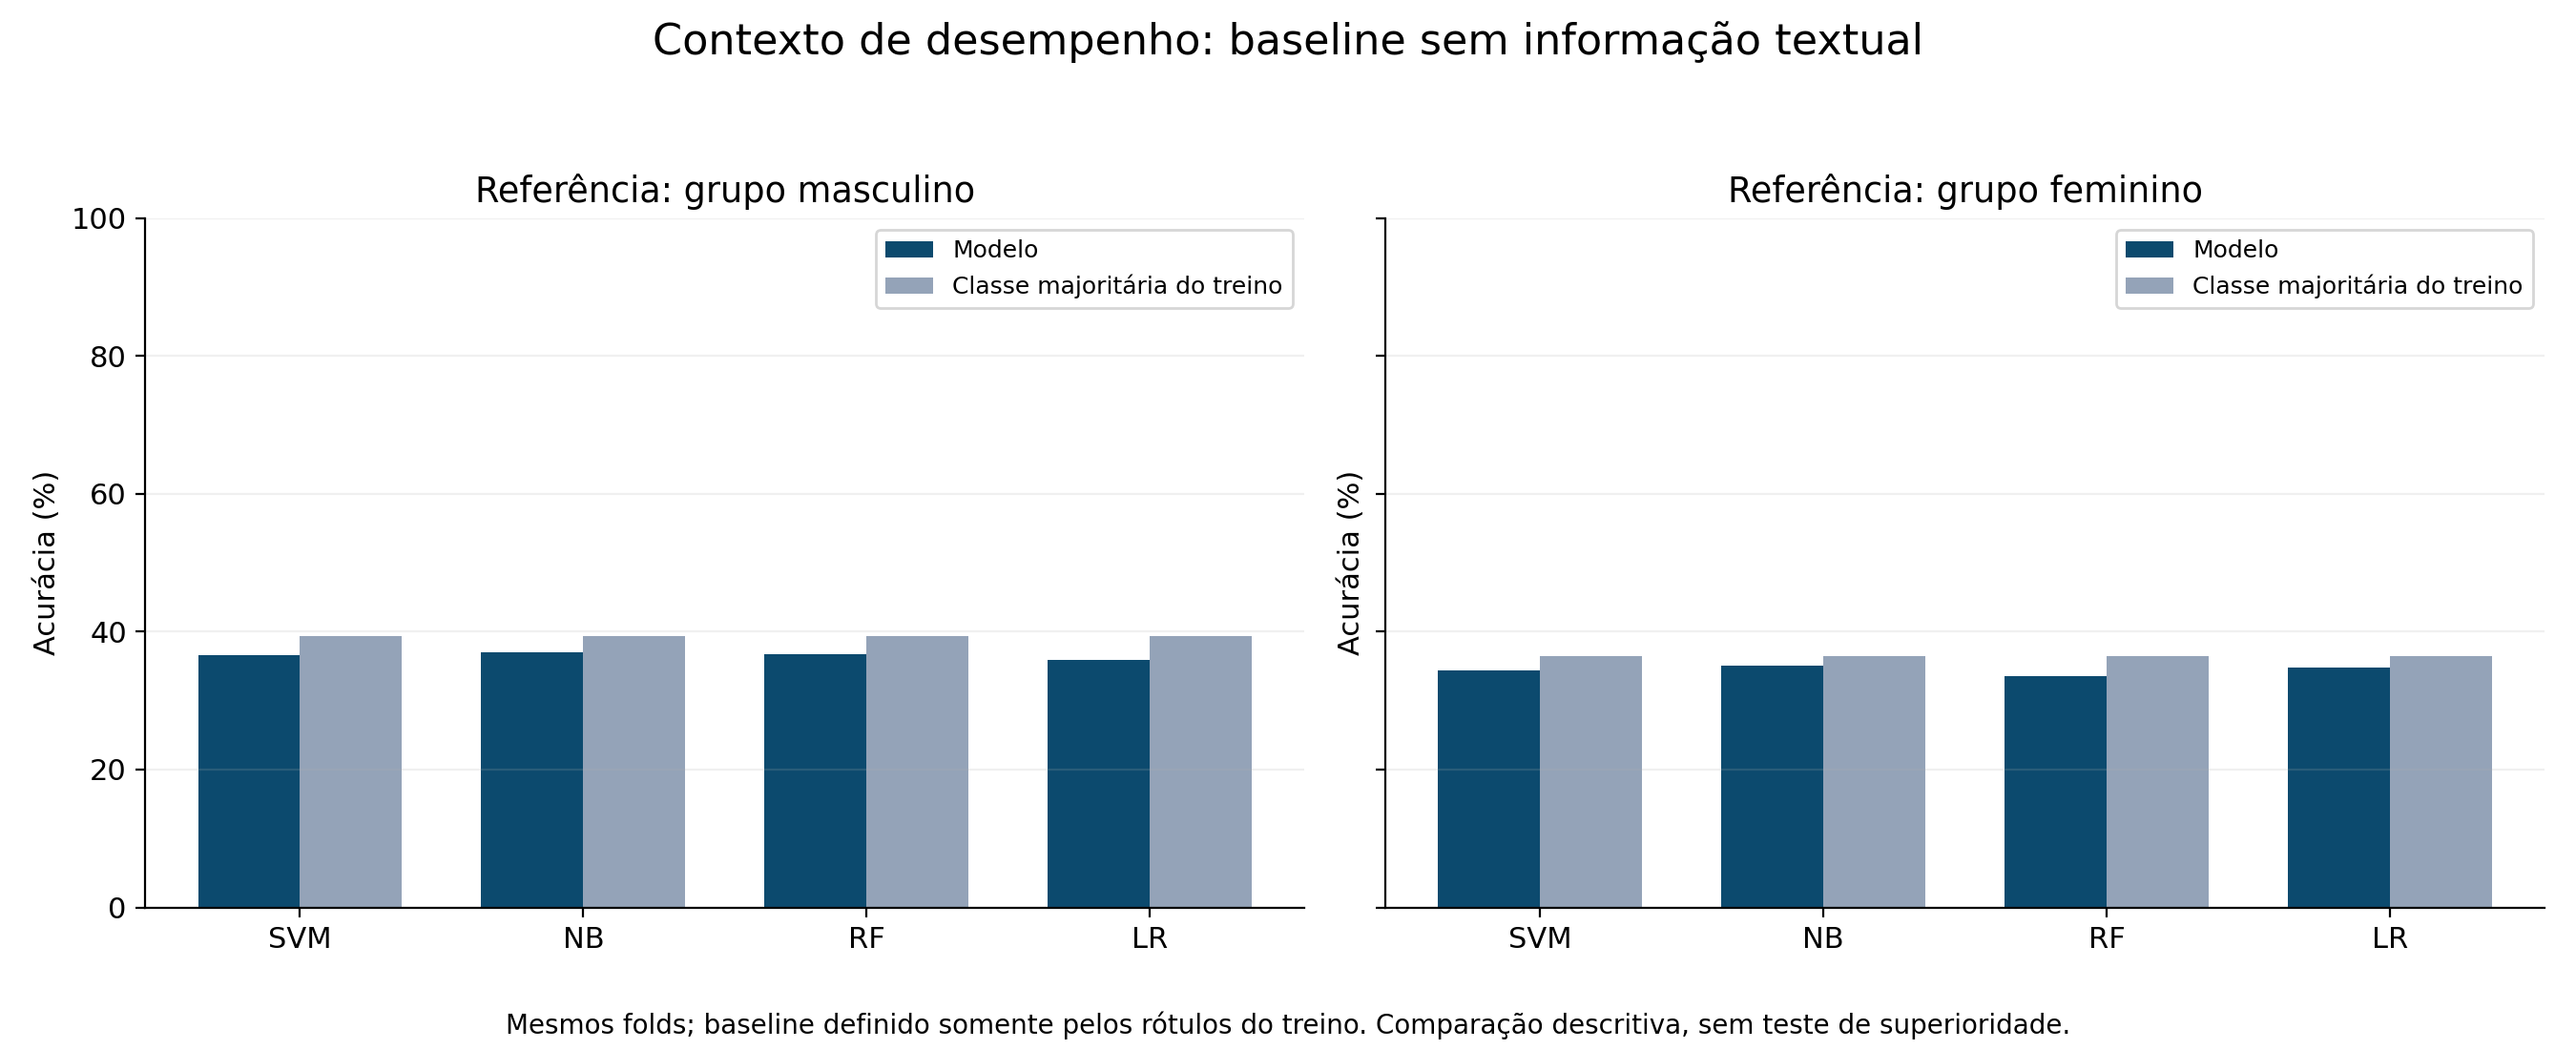

In [5]:
display(Image(filename=str(mod.OUT / 'baseline-acuracia.png')))

## Diagnóstico por classe e por fold

Mapeamento confirmado no código: −1 = negativa; 0 = neutra; 1 = positiva. As métricas por classe abaixo usam as 1.222 predições out-of-fold reunidas por modelo. São um estimador diferente da média de métricas por fold, sobretudo para F1. Não substituir uma agregação pela outra nos slides sem identificar a mudança.


In [6]:
display(tabelas['metricas-por-classe'])

modelo,grupo,classe,sentimento,precisao,revocacao,f1,suporte
SVM,masculino,-1,negativa,0.377049,0.408889,0.392324,450
SVM,masculino,0,neutra,0.200000,0.065292,0.098446,291
SVM,masculino,1,positiva,0.383412,0.509356,0.437500,481
SVM,feminino,-1,negativa,0.381890,0.434978,0.406709,446
SVM,feminino,0,neutra,0.297491,0.227397,0.257764,365
SVM,feminino,1,positiva,0.328736,0.347932,0.338061,411
NB,masculino,-1,negativa,0.367615,0.373333,0.370452,450
NB,masculino,0,neutra,0.190476,0.027491,0.048048,291
NB,masculino,1,positiva,0.381743,0.573805,0.458472,481
NB,feminino,-1,negativa,0.370432,0.500000,0.425573,446


In [7]:
display(tabelas['metricas-por-fold'])

modelo,grupo,fold,n,acuracia,f1_ponderado,f1_macro,baseline_classe,baseline_acuracia,baseline_f1_ponderado
SVM,masculino,1,245,0.363265,0.339805,0.310064,1,0.391837,0.220624
SVM,masculino,2,245,0.391837,0.355070,0.320602,1,0.395918,0.224585
SVM,masculino,3,244,0.331967,0.309864,0.282977,1,0.393443,0.222179
SVM,masculino,4,244,0.381148,0.361178,0.335633,1,0.393443,0.222179
SVM,masculino,5,244,0.364754,0.329126,0.291346,1,0.393443,0.222179
SVM,feminino,1,245,0.297959,0.285237,0.284146,-1,0.342857,0.175076
SVM,feminino,2,245,0.351020,0.348613,0.340393,-1,0.379592,0.208888
SVM,feminino,3,244,0.364754,0.361872,0.358564,-1,0.356557,0.187435
SVM,feminino,4,244,0.340164,0.341411,0.333972,-1,0.393443,0.222179
SVM,feminino,5,244,0.364754,0.360398,0.353385,-1,0.352459,0.183706


In [8]:
display(tabelas['metricas-oof-reunidas'])

modelo,grupo,n,acuracia,f1_ponderado,f1_macro
SVM,masculino,1222,0.366612,0.340124,0.309423
SVM,feminino,1222,0.343699,0.339132,0.334178
NB,masculino,1222,0.369885,0.328323,0.292324
NB,feminino,1222,0.350245,0.339045,0.332919
RF,masculino,1222,0.367430,0.343075,0.312348
RF,feminino,1222,0.335516,0.332818,0.329188
LR,masculino,1222,0.359247,0.335597,0.306837
LR,feminino,1222,0.348609,0.344351,0.339956


## Referência cruzada — análise exploratória

Modelo treinado no grupo masculino avaliado contra a referência feminina e vice-versa, sobre os mesmos itens out-of-fold. Esta tabela mede aderência à outra fonte, não corrige o resultado oficial e não transforma nenhum grupo em árbitro. Valores agregados nas predições reunidas; não são médias dos folds.


In [9]:
display(tabelas['referencia-cruzada-exploratoria'])

modelo,modelo_treinado_em,referencia,acuracia,f1_ponderado
SVM,masculino,feminino,0.349427,0.320016
SVM,feminino,masculino,0.341244,0.339274
NB,masculino,feminino,0.341244,0.293787
NB,feminino,masculino,0.352700,0.344358
RF,masculino,feminino,0.341244,0.314930
RF,feminino,masculino,0.335516,0.335055
LR,masculino,feminino,0.338789,0.311202
LR,feminino,masculino,0.345336,0.342923


## Fase sintética: o que é e o que não é recuperável

Existem referências sintéticas geradas (`rotulo_masculino` e `rotulo_feminino`), portanto seria possível calcular acurácia/F1 **contra essas referências** durante a avaliação. Entretanto, a função `treinar_e_comparar` da Fase 3 usa as predições transitoriamente e não exporta acurácia/F1 nem predições individuais. Os CSV consolidados de κ, χ² e V de Cramér não determinam essas métricas. **Não disponível não significa zero.**

Este suplemento não inventa valores sintéticos nem refaz os treinamentos. Para obtê-los, seria necessário executar avaliação adicional isolada, preservando parâmetros e verificando κ contra os resultados certificados. Os textos sintéticos são tokens aleatórios gerados sem vínculo semântico com os rótulos: acurácia/F1 nesse experimento seriam um diagnóstico do controle sintético, não evidência de competência em sentimento.

## Conteúdo sugerido para os slides de reserva

**Slide 1 — O que conta como referência?** “A MADA não pressupõe um ground truth único. Acurácia e F1 são reportados relativamente aos consensos majoritários de cada grupo; Δκ mede a mudança de concordância entre fontes e modelos.”

**Slide 2 — Aderência às fontes.** Usar a tabela principal e `acuracia-f1-fontes.png`; identificar média de cinco folds, F1 ponderado e DP. Não chamar a concordância entre predições de acurácia.

**Slide 3 — Contexto e limites.** Usar `baseline-acuracia.png`. “Todos os modelos ficam abaixo da classe majoritária em acurácia, mas acima dela em F1 ponderado. Os valores modestos limitam a interpretação da amplificação como reprodução de perspectivas aprendidas.”

**Slide 4 — Controle sintético.** “Há rótulos sintéticos de referência; acurácia/F1 não foram exportados no experimento certificado e não são recuperáveis de κ. O controle não representa compreensão semântica.”

## Rastreabilidade e definições

Entradas: `predicoes-completas.csv`, `metricas-modelos-pareados.csv` e corpus `mqd-1222-majoritarias.csv`. Verificadas cobertura, unicidade, pareamento dos folds, alinhamento de rótulos/textos e reprodução dos valores certificados. Hashes SHA-256 e versões estão em `dados/06-suplemento-qualificacao/verificacao.json`.

Definições: [acurácia — scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.accuracy_score.html) e [F1 — scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.f1_score.html). Ambos exigem `y_true`; a interpretação da referência depende do desenho do estudo.
